In [1]:
!pip install yfinance

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from datetime import datetime

In [21]:
df =  yf.download(tickers = "NFLX")
df

/tmp/ipykernel_1292/4170528829.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df =  yf.download(tickers = "NFLX")
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,NFLX,NFLX,NFLX,NFLX,NFLX
Date,,,,,
2026-09-14,80.320000,81.019997,78.489998,78.970001,30945100
2026-09-15,77.900002,79.480003,77.459999,79.379997,28027400
2026-09-16,76.410004,77.800003,76.309998,77.730003,25376300
2026-09-17,75.309998,76.959999,75.300003,76.910004,28167600
2026-09-18,71.790001,72.379997,70.110001,71.269997,114413500
2026-09-21,73.360001,73.870003,71.790001,71.820000,36948000
2026-09-22,72.160004,73.760002,71.580002,73.690002,34372500
2026-09-23,71.360001,72.370003,71.070000,72.080002,32807500


In [22]:
# print the metadata of the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 21 entries, 2026-09-14 to 2026-10-12
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, NFLX)   21 non-null     float64
 1   (High, NFLX)    21 non-null     float64
 2   (Low, NFLX)     21 non-null     float64
 3   (Open, NFLX)    21 non-null     float64
 4   (Volume, NFLX)  21 non-null     int64  
dtypes: float64(4), int64(1)
memory usage: 1008.0 bytes


In [23]:
# data description
df.describe()

Price,Close,High,Low,Open,Volume
Ticker,NFLX,NFLX,NFLX,NFLX,NFLX
count,21.000000,21.000000,21.000000,21.000000,2.100000e+01
mean,71.621906,72.557620,70.966191,71.880001,3.649188e+07
std,3.417753,3.589537,3.351695,3.584077,1.938016e+07
min,67.059998,67.500000,66.540001,67.050003,1.177838e+07
25%,69.580002,70.300003,68.879997,70.089996,2.822390e+07
50%,71.150002,71.839996,70.190002,71.330002,3.437250e+07
75%,72.160004,73.760002,71.580002,72.080002,3.694800e+07
max,80.320000,81.019997,78.489998,79.379997,1.144135e+08


In [24]:
print(df.isnull().sum())

Price   Ticker
Close   NFLX      0
High    NFLX      0
Low     NFLX      0
Open    NFLX      0
Volume  NFLX      0
dtype: int64


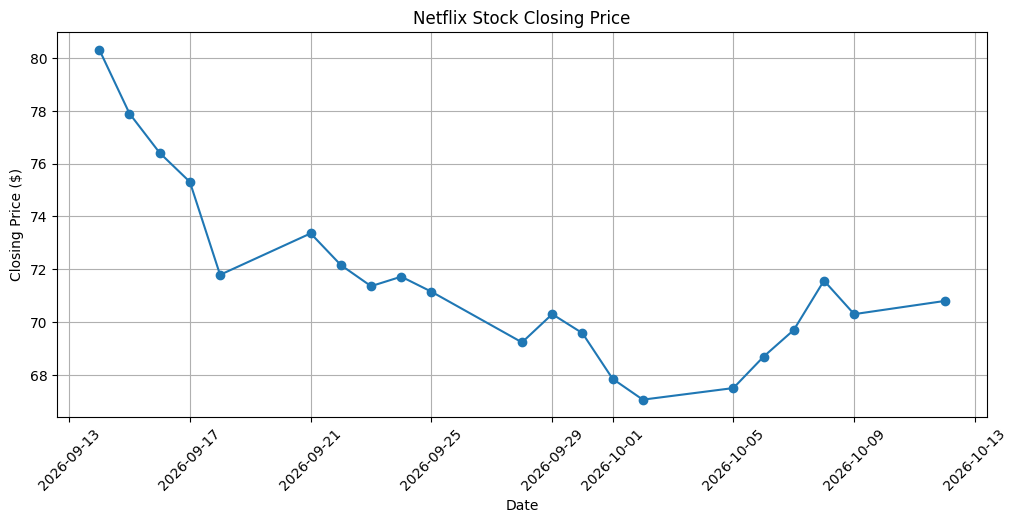

In [26]:
plt.figure(figsize=(12,5))
plt.plot(df.index, df['Close'], marker='o')
plt.title('Netflix Stock Closing Price')
plt.xlabel('Date')
plt.ylabel('Closing Price ($)')
plt.xticks(rotation=45)
plt.grid()
plt.show()

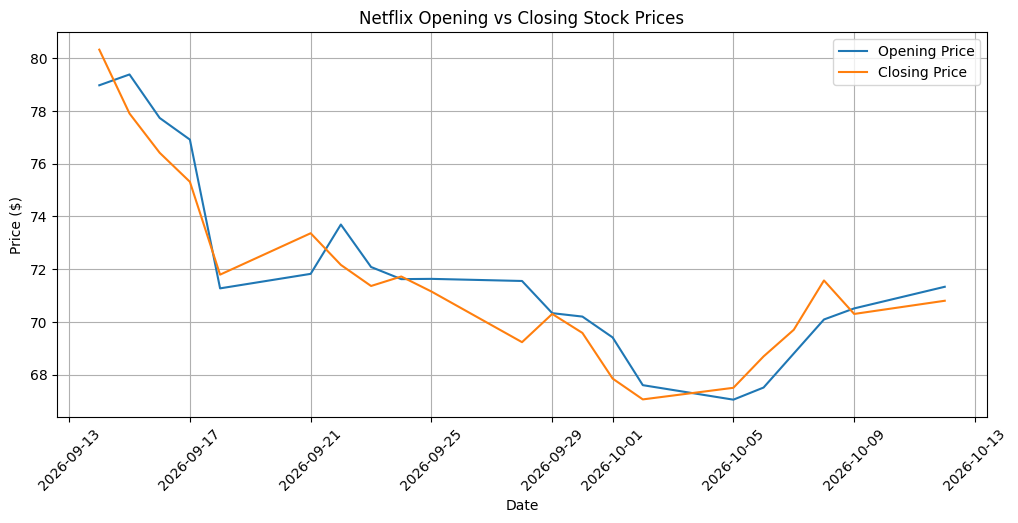

In [27]:
plt.figure(figsize=(12,5))
plt.plot(df.index, df['Open'], label='Opening Price')
plt.plot(df.index, df['Close'], label='Closing Price')

plt.title('Netflix Opening vs Closing Stock Prices')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.legend()
plt.xticks(rotation=45)
plt.grid()
plt.show()

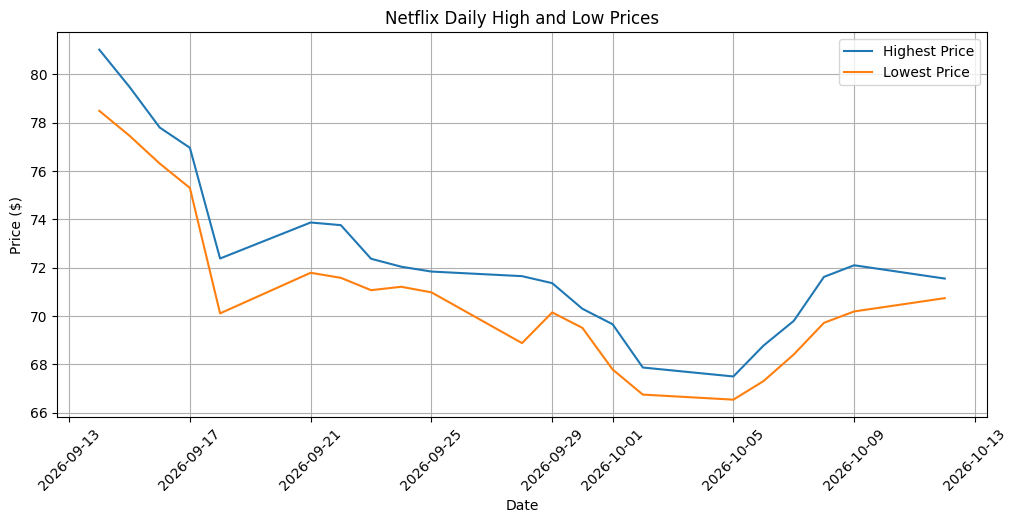

In [28]:
plt.figure(figsize=(12,5))
plt.plot(df.index, df['High'], label='Highest Price')
plt.plot(df.index, df['Low'], label='Lowest Price')

plt.title('Netflix Daily High and Low Prices')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.legend()
plt.xticks(rotation=45)
plt.grid()
plt.show()

In [32]:
df['Price_Change'] = df['Close'].diff()
df[['Close', 'Price_Change']].tail()

Price,Close,Price_Change
Ticker,NFLX,
Date,,
2026-10-06,68.690002,1.190002
2026-10-07,69.699997,1.009995
2026-10-08,71.570000,1.870003
2026-10-09,70.300003,-1.269997
2026-10-12,70.800003,0.500000


In [33]:
df['Daily_Return'] = df['Close'].pct_change() * 100
df[['Close', 'Daily_Return']].tail()

Price,Close,Daily_Return
Ticker,NFLX,
Date,,
2026-10-06,68.690002,1.762967
2026-10-07,69.699997,1.470366
2026-10-08,71.570000,2.682931
2026-10-09,70.300003,-1.774482
2026-10-12,70.800003,0.711238


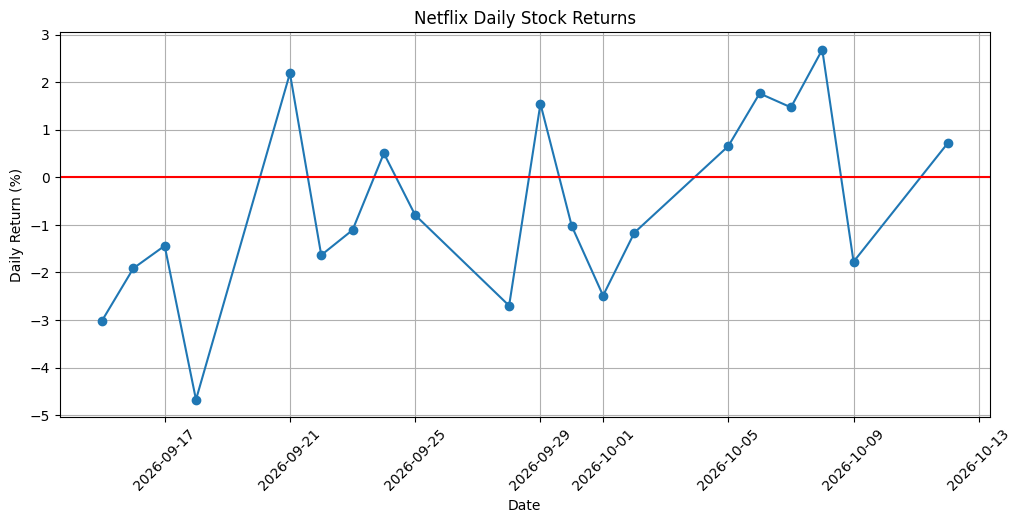

In [34]:
plt.figure(figsize=(12,5))
plt.plot(df.index, df['Daily_Return'], marker='o')

plt.title('Netflix Daily Stock Returns')
plt.xlabel('Date')
plt.ylabel('Daily Return (%)')
plt.axhline(0, color='red')
plt.xticks(rotation=45)
plt.grid()
plt.show()

In [35]:
print("Maximum Closing Price:", df['Close'].max())
print("Minimum Closing Price:", df['Close'].min())
print("Average Closing Price:", df['Close'].mean())
print("Date of Highest Closing Price:", df['Close'].idxmax())
print("Date of Lowest Closing Price:", df['Close'].idxmin())

Maximum Closing Price: Ticker
NFLX    80.32
dtype: float64
Minimum Closing Price: Ticker
NFLX    67.059998
dtype: float64
Average Closing Price: Ticker
NFLX    71.621906
dtype: float64
Date of Highest Closing Price: Ticker
NFLX   2026-09-14
dtype: datetime64[ns]
Date of Lowest Closing Price: Ticker
NFLX   2026-10-02
dtype: datetime64[ns]


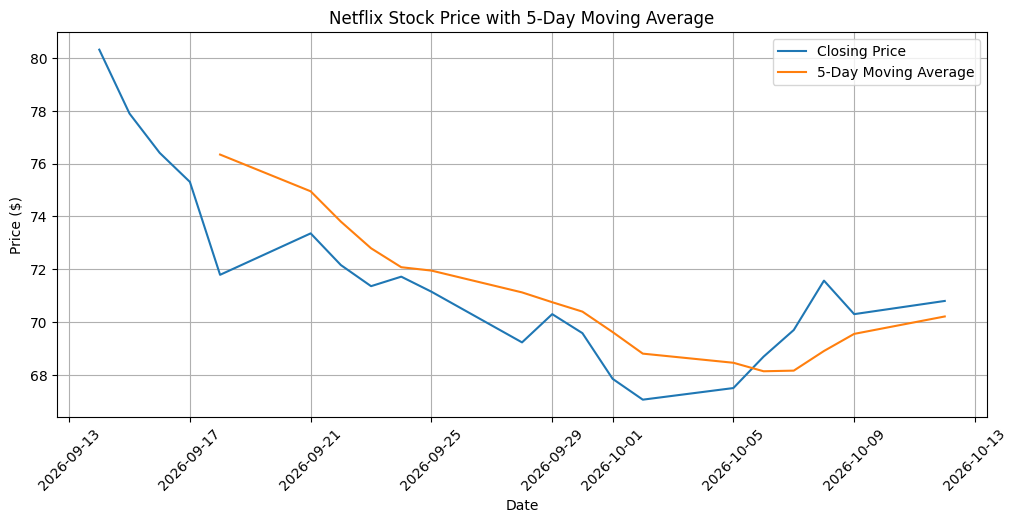

In [36]:
df['Moving_Average'] = df['Close'].rolling(window=5).mean()

plt.figure(figsize=(12,5))
plt.plot(df.index, df['Close'], label='Closing Price')
plt.plot(df.index, df['Moving_Average'], label='5-Day Moving Average')

plt.title('Netflix Stock Price with 5-Day Moving Average')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.legend()
plt.xticks(rotation=45)
plt.grid()
plt.show()